In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

# Thesis Model — Built From Scratch (NumPy, Manual Backprop)

This notebook rebuilds the core of the thesis model (3R robot arm inverse kinematics) as a **plain feedforward neural network implemented from scratch**, in the style of Andrew Ng's Deep Learning Specialization (Course 1/2 assignments):

- No PyTorch, no autograd — every gradient is derived and coded by hand.
- No mixture density network yet — a single deterministic output head, trained with MSE. The target is `[sin(theta1), cos(theta1), theta2, theta3]` (`theta1` is sin/cos-encoded to remove its +-180 degree wraparound discontinuity; `theta2`/`theta3` stay as raw radians since they never wrap).
- Input is `[x, y, z, elbow_config]` (v3) — `elbow_config` is a known, oracle input at training time that resolves the theta2/theta3 elbow-branch ambiguity (see Section 1). At inference the caller only supplies `(x,y,z)`; `predict_ik` (Section 4) queries both elbow configurations and picks whichever reprojects closer via forward kinematics.
- No optimizer beyond plain (batch) gradient descent — this is the baseline to get working correctly before adding Adam, mini-batching, or mixture outputs later.

**Structure:**
1. Data Generation — sample joint angles, compute forward kinematics, build the `(position -> angles)` dataset.
2. Helper / Utility Functions — activations and their derivatives, error-metric helpers.
3. Neural Network Model — parameter initialization, forward propagation, cost computation, backward propagation, parameter updates, and the full training loop.
4. Analysis — train the model, inspect the cost curve, and evaluate prediction accuracy.

## 1. Data Generation

The robot is a 3R arm: a base yaw joint `theta1`, plus a 2-link planar arm (`theta2`, `theta3`) that moves in the `(r, z)` plane swept out by that yaw.

```
r = L1 + L2*cos(theta2) + L3*cos(theta2 + theta3)
z = L2*sin(theta2) + L3*sin(theta2 + theta3)
x = r*cos(theta1)
y = r*sin(theta1)
```

We sample joint angles uniformly within their limits, compute the resulting end-effector position via forward kinematics, and treat `(x, y, z) -> (theta1, theta2, theta3)` as the supervised regression problem. Inputs and targets are both standardized (zero mean, unit variance) using train-set statistics only.

### Angle Encoding: sin/cos for theta1

`theta1` ranges over the full circle (-180°, 180°]. Two physically near-identical directions right at the wrap boundary — e.g. 179° and -179° — are numerically far apart as raw radians. A network regressing raw `theta1` is forced to fit a discontinuous function right at that boundary, which shows up as large error there (see `QUESTIONS.md`, Q1).

Fix: don't regress `theta1` directly. Regress `[sin(theta1), cos(theta1)]` instead — a continuous, wraparound-free representation — and recover the angle afterwards with `atan2(sin, cos)`, which is exact and lossless. `theta2`/`theta3` stay as raw radians since they're limited to (-90°, 90°) and never wrap.

The network's target now has **4 components**: `[sin(theta1), cos(theta1), theta2, theta3]`.

### Elbow Configuration Input (v3): removing the theta2/theta3 branch ambiguity

For a given `(x, y, z)`, there are generally **two** valid `(theta2, theta3)` solutions — "elbow up" and "elbow down" — that reach the exact same position (the planar 2-link sub-chain is a classic 2-to-1 inverse map). A single deterministic network fed only `(x, y, z)` cannot represent this: wherever the two branches are close together in input space, its MSE-optimal prediction is the *average* of both branches, which is generally not a valid solution at all. This is the dominant reason `theta3`'s error has stayed large across v1/v2 above.

**Fix (v3):** tell the network which branch to solve for. Add a 4th input, `elbow_config`, derived exactly from the already-known `theta3` at data-generation time:

$$
\text{elbow\_config} = \begin{cases} +1 & \theta_3 \geq 0 \\ -1 & \theta_3 < 0 \end{cases}
$$

With `elbow_config` known, the mapping `(x, y, z, elbow_config) -> (theta1, theta2, theta3)` is single-valued — no more averaging conflicting branches. `elbow_config` is left un-normalized (like `sin`/`cos` earlier), since ±1 is already a clean, bounded, symmetric value.

**But the caller of the trained model only has `(x, y, z)`** — they don't know the branch in advance. So at inference, `predict_ik` queries the network with *both* `elbow_config = +1` and `elbow_config = -1`, decodes both candidate angle triples, runs each through forward kinematics, and returns whichever one's reprojected position is closer to the requested `(x, y, z)`. The network never has to guess the branch; the branch choice is resolved by checking which one is physically consistent.

(Flagged for future reference, not implemented: an alternative would be to use the branch label only as a *training-time* signal for a 2-head architecture that still takes just `(x,y,z)` as input — see `thesis_doc.md`, §6.6.)

In [ ]:
## ---- Robot parameters ----
L1, L2, L3 = 1.0, 1.0, 0.5
THETA1_LIM = (-np.pi, np.pi)
THETA2_LIM = (-np.pi / 2, np.pi / 2)
THETA3_LIM = (-np.pi / 2, np.pi / 2)


def forward_kinematics(theta1, theta2, theta3, L1=L1, L2=L2, L3=L3):
    """Vectorized FK: joint angles (1D arrays) -> end-effector position (x, y, z)."""
    r = L1 + L2 * np.cos(theta2) + L3 * np.cos(theta2 + theta3)
    z = L2 * np.sin(theta2) + L3 * np.sin(theta2 + theta3)
    x = r * np.cos(theta1)
    y = r * np.sin(theta1)
    return x, y, z


## ---- theta1 sin/cos encoding (removes the +-180 deg wraparound discontinuity) ----
def encode_theta1_sincos(Y_theta):
    """Y_theta: (3, m) raw [theta1, theta2, theta3] -> (4, m) [sin1, cos1, theta2, theta3]."""
    theta1, theta2, theta3 = Y_theta[0], Y_theta[1], Y_theta[2]
    return np.vstack([np.sin(theta1), np.cos(theta1), theta2, theta3])


def decode_theta1_sincos(Y_enc):
    """Y_enc: (4, m) [sin1, cos1, theta2, theta3] -> (3, m) raw [theta1, theta2, theta3].

    atan2 recovers theta1 exactly regardless of the magnitude of sin1/cos1,
    so this is robust even if the network's raw predictions don't exactly
    satisfy sin^2 + cos^2 = 1.
    """
    sin1, cos1, theta2, theta3 = Y_enc[0], Y_enc[1], Y_enc[2], Y_enc[3]
    theta1 = np.arctan2(sin1, cos1)
    return np.vstack([theta1, theta2, theta3])


## ---- elbow configuration (removes the theta2/theta3 branch ambiguity) ----
def encode_elbow_config(Y_theta_raw):
    """Y_theta_raw: (3, m) raw [theta1, theta2, theta3] -> (1, m) elbow_config in {+1, -1}.

    +1 if theta3 >= 0 (one branch), -1 if theta3 < 0 (the other branch).
    Exact and free, since theta3 is already known at data-generation time.
    """
    theta3 = Y_theta_raw[2]
    return np.where(theta3 >= 0.0, 1.0, -1.0)[None, :]


def generate_dataset(n_samples, seed=0):
    """Sample random joint configurations and return (X, Y) with examples as columns.

    X: (3, n_samples) end-effector positions [x, y, z]
    Y: (3, n_samples) RAW joint angles [theta1, theta2, theta3] (encoded later)
    """
    rng = np.random.default_rng(seed)
    theta1 = rng.uniform(*THETA1_LIM, n_samples)
    theta2 = rng.uniform(*THETA2_LIM, n_samples)
    theta3 = rng.uniform(*THETA3_LIM, n_samples)

    x, y, z = forward_kinematics(theta1, theta2, theta3)

    X = np.vstack([x, y, z])
    Y = np.vstack([theta1, theta2, theta3])
    return X, Y


# ---- Generate + split (raw angles, raw xyz -- no elbow_config yet) ----
N_SAMPLES = 30000
X_all_xyz, Y_all_raw = generate_dataset(N_SAMPLES, seed=0)

n_train = int(0.8 * N_SAMPLES)
n_dev = int(0.1 * N_SAMPLES)

X_train_xyz, Y_train_raw = X_all_xyz[:, :n_train], Y_all_raw[:, :n_train]
X_dev_xyz, Y_dev_raw = X_all_xyz[:, n_train:n_train + n_dev], Y_all_raw[:, n_train:n_train + n_dev]
X_test_xyz, Y_test_raw = X_all_xyz[:, n_train + n_dev:], Y_all_raw[:, n_train + n_dev:]

print(f"train: {X_train_xyz.shape[1]}  dev: {X_dev_xyz.shape[1]}  test: {X_test_xyz.shape[1]}")

# ---- Encode targets: theta1 -> (sin, cos); theta2, theta3 stay raw ----
Y_train = encode_theta1_sincos(Y_train_raw)
Y_dev = encode_theta1_sincos(Y_dev_raw)
Y_test = encode_theta1_sincos(Y_test_raw)

# ---- Build TRAINING inputs: append the oracle elbow_config to raw (x,y,z) ----
# NOTE: X_train/X_dev/X_test (4, m) are for TRAINING only -- they include the
# ground-truth elbow_config, which is not available at inference. Inference
# uses X_*_xyz (3, m) directly via predict_ik (Section 4), which queries both
# elbow_config values itself.
X_train = np.vstack([X_train_xyz, encode_elbow_config(Y_train_raw)])
X_dev = np.vstack([X_dev_xyz, encode_elbow_config(Y_dev_raw)])
X_test = np.vstack([X_test_xyz, encode_elbow_config(Y_test_raw)])

# ---- Standardize using train-set statistics only ----
# sin1/cos1 (Y rows 0-1) and elbow_config (X row 3) are already in [-1, 1]
# with mean ~0 -- leave them un-normalized (identity mean=0, std=1) so
# decoding never has to undo a normalization before atan2, and elbow_config
# stays exactly +-1. theta2/theta3 (Y rows 2-3) and x,y,z (X rows 0-2) still
# get standard z-score normalization.
xyz_mean, xyz_std = X_train_xyz.mean(axis=1, keepdims=True), X_train_xyz.std(axis=1, keepdims=True)
X_mean = np.vstack([xyz_mean, np.zeros((1, 1))])
X_std = np.vstack([xyz_std, np.ones((1, 1))])

theta23_mean = Y_train[2:4].mean(axis=1, keepdims=True)
theta23_std = Y_train[2:4].std(axis=1, keepdims=True)
Y_mean = np.vstack([np.zeros((2, 1)), theta23_mean])
Y_std = np.vstack([np.ones((2, 1)), theta23_std])


def normalize(A, mean, std):
    return (A - mean) / std


def denormalize(A_norm, mean, std):
    return A_norm * std + mean


X_train_norm, Y_train_norm = normalize(X_train, X_mean, X_std), normalize(Y_train, Y_mean, Y_std)
X_dev_norm, Y_dev_norm = normalize(X_dev, X_mean, X_std), normalize(Y_dev, Y_mean, Y_std)
X_test_norm, Y_test_norm = normalize(X_test, X_mean, X_std), normalize(Y_test, Y_mean, Y_std)

print("X_train_norm mean/std:", X_train_norm.mean(axis=1).round(3), X_train_norm.std(axis=1).round(3))
print("Y_train_norm mean/std:", Y_train_norm.mean(axis=1).round(3), Y_train_norm.std(axis=1).round(3))

train: 24000  dev: 3000  test: 3000
X_train_norm mean/std: [-0.     0.     0.    -0.008] [1. 1. 1. 1.]
Y_train_norm mean/std: [ 0.008  0.009 -0.    -0.   ] [0.705 0.709 1.    1.   ]


## 2. Helper / Utility Functions

Reusable pieces that aren't themselves one of the five core NN steps: activation functions with their derivatives (needed by forward and backward propagation), and error-metric helpers used later in the analysis section.

In [ ]:
## ---- Activation functions (forward) ----
def relu(Z):
    return np.maximum(0, Z)


def linear(Z):
    return Z


## ---- Activation derivatives (backward): dZ = dA * activation'(Z) ----
def relu_backward(dA, Z):
    dZ = np.array(dA, copy=True)
    dZ[Z <= 0] = 0
    return dZ


def linear_backward(dA, Z):
    return np.array(dA, copy=True)


## ---- Error-metric helpers (used in Section 4) ----
def mae_degrees(pred_theta, true_theta):
    """Mean absolute *circular* error per joint, in degrees. Inputs shape (3, m), radians.

    Uses the shortest angular distance rather than a plain difference: raw
    angle values wrap at +-180 degrees (relevant to theta1). Without this, a
    perfectly good prediction near the wrap boundary (true=179 deg,
    pred=-179 deg) would be scored as a ~358 degree error instead of the
    true ~2 degrees.
    """
    diff = pred_theta - true_theta
    diff = (diff + np.pi) % (2 * np.pi) - np.pi  # wrap to (-pi, pi]
    return np.mean(np.abs(diff), axis=1) * (180.0 / np.pi)


def pose_error_mm(pred_theta, true_xyz, meters_to_mm=1000.0):
    """Euclidean end-effector error (mm) between FK(predicted angles) and the true target position."""
    x_pred, y_pred, z_pred = forward_kinematics(pred_theta[0], pred_theta[1], pred_theta[2])
    pred_xyz = np.vstack([x_pred, y_pred, z_pred])
    return np.linalg.norm(pred_xyz - true_xyz, axis=0) * meters_to_mm

## 3. Neural Network Model

A plain fully-connected network: ReLU hidden layers, a linear (identity) output layer, trained with mean-squared error and plain batch gradient descent. Every step below is written out explicitly rather than relying on a framework — this is the baseline to verify correctness before adding optimizers or a mixture output head.

### 3.1 Parameter Initialization

Weights use He initialization (`* sqrt(2 / n_prev)`), appropriate for ReLU hidden layers; biases start at zero.

In [ ]:
def initialize_parameters(layer_dims, seed=1):
    """layer_dims: list like [n_x, n_h1, n_h2, ..., n_y]. Returns dict of W1,b1,...,WL,bL."""
    rng = np.random.default_rng(seed)
    parameters = {}
    L = len(layer_dims)

    for l in range(1, L):
        parameters[f"W{l}"] = rng.standard_normal((layer_dims[l], layer_dims[l - 1])) * np.sqrt(2.0 / layer_dims[l - 1])
        parameters[f"b{l}"] = np.zeros((layer_dims[l], 1))

    return parameters


# sanity check (input dim = 4: x,y,z,elbow_config; output dim = 4, matching the sin/cos-encoded target)
_p = initialize_parameters([4, 5, 4, 4])
for k, v in _p.items():
    print(k, v.shape)

W1 (5, 4)
b1 (5, 1)
W2 (4, 5)
b2 (4, 1)
W3 (4, 4)
b3 (4, 1)


### 3.2 Forward Propagation

Each layer computes `Z = W . A_prev + b` then applies its activation (ReLU for hidden layers, linear for the output layer). Every layer's `(A_prev, W, b, Z)` is cached — backward propagation needs all of it.

In [ ]:
def linear_activation_forward(A_prev, W, b, activation):
    Z = W.dot(A_prev) + b

    if activation == "relu":
        A = relu(Z)
    elif activation == "linear":
        A = linear(Z)
    else:
        raise ValueError(f"Unknown activation: {activation}")

    cache = (A_prev, W, b, Z)
    return A, cache


def forward_propagation(X, parameters):
    """Runs the full network: ReLU on every hidden layer, linear on the output layer.

    Returns AL (network output, shape (n_y, m)) and the list of per-layer caches.
    """
    caches = []
    A = X
    L = len(parameters) // 2

    for l in range(1, L):
        A_prev = A
        A, cache = linear_activation_forward(A_prev, parameters[f"W{l}"], parameters[f"b{l}"], activation="relu")
        caches.append(cache)

    AL, cache = linear_activation_forward(A, parameters[f"W{L}"], parameters[f"b{L}"], activation="linear")
    caches.append(cache)

    return AL, caches


# sanity check
_AL, _caches = forward_propagation(X_train_norm[:, :5], _p)
print("AL shape:", _AL.shape, " num caches:", len(_caches))

AL shape: (4, 5)  num caches: 3


### 3.3 Cost Computation

Mean squared error, averaged over both examples and output dimensions:

```
J = (1 / 2m) * sum((AL - Y)^2)
```

The `1/2` is a convenience so the gradient `dJ/dAL = (AL - Y) / m` comes out clean.

In [ ]:
def compute_cost(AL, Y):
    m = Y.shape[1]
    cost = (1.0 / (2 * m)) * np.sum((AL - Y) ** 2)
    return float(np.squeeze(cost))


# sanity check
print("cost:", compute_cost(_AL, Y_train_norm[:, :5]))

cost: 1.3349549303095767


### 3.4 Backward Propagation

Starting from `dAL = AL - Y` (the derivative of the *sum* term; the `1/m` averaging is applied once, inside the `dW`/`db` formulas below — not here, to avoid double-counting it at every layer), propagate gradients backward layer by layer using the cached `(A_prev, W, b, Z)` from the forward pass:

```
dZ = dA * activation'(Z)
dW = (1/m) * dZ . A_prev^T
db = (1/m) * sum(dZ, axis=1)
dA_prev = W^T . dZ
```

In [ ]:
def linear_activation_backward(dA, cache, activation):
    A_prev, W, b, Z = cache
    m = A_prev.shape[1]

    if activation == "relu":
        dZ = relu_backward(dA, Z)
    elif activation == "linear":
        dZ = linear_backward(dA, Z)
    else:
        raise ValueError(f"Unknown activation: {activation}")

    dW = (1.0 / m) * dZ.dot(A_prev.T)
    db = (1.0 / m) * np.sum(dZ, axis=1, keepdims=True)
    dA_prev = W.T.dot(dZ)

    return dA_prev, dW, db


def backward_propagation(AL, Y, caches):
    """Returns a dict of gradients: dW1,db1,...,dWL,dbL (plus intermediate dA's)."""
    grads = {}
    L = len(caches)

    # NOTE: no /m here — the 1/m averaging happens exactly once, inside
    # linear_activation_backward's dW/db computation. Dividing here too would
    # double-count it at every layer during backprop.
    dAL = AL - Y

    current_cache = caches[L - 1]
    dA_prev, dW, db = linear_activation_backward(dAL, current_cache, activation="linear")
    grads[f"dW{L}"] = dW
    grads[f"db{L}"] = db
    grads[f"dA{L - 1}"] = dA_prev

    for l in reversed(range(1, L)):
        current_cache = caches[l - 1]
        dA_prev, dW, db = linear_activation_backward(grads[f"dA{l}"], current_cache, activation="relu")
        grads[f"dW{l}"] = dW
        grads[f"db{l}"] = db
        grads[f"dA{l - 1}"] = dA_prev

    return grads


# sanity check
_grads = backward_propagation(_AL, Y_train_norm[:, :5], _caches)
for k in sorted(_grads.keys()):
    print(k, _grads[k].shape)

dA0 (4, 5)
dA1 (5, 5)
dA2 (4, 5)
dW1 (5, 4)
dW2 (4, 5)
dW3 (4, 4)
db1 (5, 1)
db2 (4, 1)
db3 (4, 1)


### 3.5 Update Parameters

Plain gradient descent — no momentum, no Adam (that comes later):

```
W := W - learning_rate * dW
b := b - learning_rate * db
```

In [ ]:
def update_parameters(parameters, grads, learning_rate):
    L = len(parameters) // 2

    for l in range(1, L + 1):
        parameters[f"W{l}"] = parameters[f"W{l}"] - learning_rate * grads[f"dW{l}"]
        parameters[f"b{l}"] = parameters[f"b{l}"] - learning_rate * grads[f"db{l}"]

    return parameters

### 3.6 Full Training Loop — `nn_model`

Wires the five steps above into a single training loop: initialize once, then repeat forward -> cost -> backward -> update for `num_iterations`.

In [ ]:
def nn_model(X, Y, layer_dims, learning_rate=0.01, num_iterations=3000, print_every=500, seed=1):
    parameters = initialize_parameters(layer_dims, seed=seed)
    costs = []

    for i in range(num_iterations):
        AL, caches = forward_propagation(X, parameters)
        cost = compute_cost(AL, Y)
        grads = backward_propagation(AL, Y, caches)
        parameters = update_parameters(parameters, grads, learning_rate)

        if i % 10 == 0:
            costs.append(cost)
        if print_every and i % print_every == 0:
            print(f"iteration {i:5d}  cost {cost:.6f}")

    print(f"iteration {num_iterations:5d}  cost {cost:.6f}  (final)")
    return parameters, costs

## 4. Analysis

Train the from-scratch network on the standardized data, check the cost curve for sane convergence, then evaluate on held-out test data: per-joint angle MAE (degrees) and end-effector pose error (mm) via forward kinematics of the predicted angles.

iteration     0  cost 7.275843
iteration   500  cost 0.126680
iteration  1000  cost 0.103020
iteration  1500  cost 0.077249
iteration  2000  cost 0.069824
iteration  2500  cost 0.043267
iteration  3000  cost 0.040235  (final)


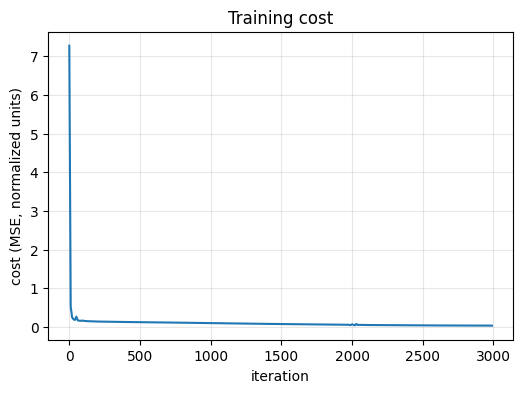

In [ ]:
layer_dims = [4, 256, 128, 64, 4]  # input (x,y,z,elbow_config) -> hidden -> hidden -> output (sin_theta1, cos_theta1, theta2, theta3)

parameters, costs = nn_model(
    X_train_norm, Y_train_norm,
    layer_dims=layer_dims,
    learning_rate=0.05,
    num_iterations=3000,
    print_every=500,
)

plt.figure(figsize=(6, 4))
plt.plot(np.arange(len(costs)) * 10, costs)
plt.xlabel("iteration")
plt.ylabel("cost (MSE, normalized units)")
plt.title("Training cost")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
## ---- Inference: caller only supplies (x,y,z); resolve elbow_config internally ----
def predict_ik(xyz_raw, parameters):
    """xyz_raw: (3, m) raw (unnormalized) target end-effector positions.

    The network was trained with elbow_config as an oracle input, so at
    inference we don't know it -- instead we query the network with BOTH
    elbow_config = +1 and -1, decode each candidate to a theta triple, run
    it back through forward kinematics, and keep whichever candidate's
    reprojected position is closer to the requested xyz_raw. This is what
    resolves the elbow ambiguity without the caller ever supplying it.

    Returns: pred_theta (3, m), chosen_elbow_config (m,), pose_err_mm (m,)
    -- the achieved FK-reprojection error of whichever candidate was picked.
    """
    m = xyz_raw.shape[1]
    candidates = {}
    for config in (1.0, -1.0):
        config_row = np.full((1, m), config)
        X_query = np.vstack([xyz_raw, config_row])
        X_query_norm = normalize(X_query, X_mean, X_std)

        AL_norm, _ = forward_propagation(X_query_norm, parameters)
        pred_enc = denormalize(AL_norm, Y_mean, Y_std)
        pred_theta = decode_theta1_sincos(pred_enc)
        pose_err = pose_error_mm(pred_theta, xyz_raw)

        candidates[config] = (pred_theta, pose_err)

    theta_pos, err_pos = candidates[1.0]
    theta_neg, err_neg = candidates[-1.0]

    use_pos = err_pos <= err_neg  # (m,)
    pred_theta = np.where(use_pos[None, :], theta_pos, theta_neg)
    chosen_elbow_config = np.where(use_pos, 1.0, -1.0)
    pose_err = np.minimum(err_pos, err_neg)

    return pred_theta, chosen_elbow_config, pose_err


## ---- Evaluate on dev + test sets ----
def evaluate(xyz_raw, Y_true_raw, parameters, split_name):
    pred_theta, chosen_elbow_config, pose_err = predict_ik(xyz_raw, parameters)

    true_elbow_config = encode_elbow_config(Y_true_raw)[0]
    config_accuracy = np.mean(chosen_elbow_config == true_elbow_config)

    joint_mae = mae_degrees(pred_theta, Y_true_raw)
    mean_angle_mae = joint_mae.mean()

    print(f"--- {split_name} ---")
    print(f"theta1 MAE: {joint_mae[0]:.3f} deg   theta2 MAE: {joint_mae[1]:.3f} deg   theta3 MAE: {joint_mae[2]:.3f} deg")
    print(f"mean angle MAE: {mean_angle_mae:.3f} deg")
    print(f"elbow-config selection accuracy (best-of-2 vs. true branch): {config_accuracy:.1%}")
    print(f"pose error: mean {pose_err.mean():.2f} mm   median {np.median(pose_err):.2f} mm   p95 {np.percentile(pose_err, 95):.2f} mm")
    print()

    return pred_theta, joint_mae, pose_err


dev_pred_theta, dev_joint_mae, dev_pose_err = evaluate(X_dev_xyz, Y_dev_raw, parameters, "dev")
test_pred_theta, test_joint_mae, test_pose_err = evaluate(X_test_xyz, Y_test_raw, parameters, "test")

--- dev ---
theta1 MAE: 1.286 deg   theta2 MAE: 14.529 deg   theta3 MAE: 44.680 deg
mean angle MAE: 20.165 deg
elbow-config selection accuracy (best-of-2 vs. true branch): 57.1%
pose error: mean 73.18 mm   median 68.38 mm   p95 136.50 mm

--- test ---
theta1 MAE: 1.290 deg   theta2 MAE: 14.778 deg   theta3 MAE: 45.732 deg
mean angle MAE: 20.600 deg
elbow-config selection accuracy (best-of-2 vs. true branch): 56.2%
pose error: mean 74.08 mm   median 68.65 mm   p95 140.34 mm



## 5. Diagnostic: is the remaining pose error singularity-driven or a general precision ceiling?

v3's mean test pose error (101.64mm) is much better than v2's (193.88mm), but still far from the thesis requirement. Before deciding whether to address singularities (oversample near `theta3≈0` / `r≈0`) or just train harder (Adam, more iterations, more capacity), check where the remaining error actually concentrates:

- Correlate pose error with `|sin(theta3)|` (elbow-singularity proximity — smaller means closer to full extension) and with `r` (base-singularity proximity — smaller means closer to the folded/degenerate configuration).
- Compare the worst-error decile's average proximity to each singularity against the overall average.
- Check whether best-of-2 branch-selection accuracy itself degrades near either singularity (plausible: the two branches may become harder to tell apart there).

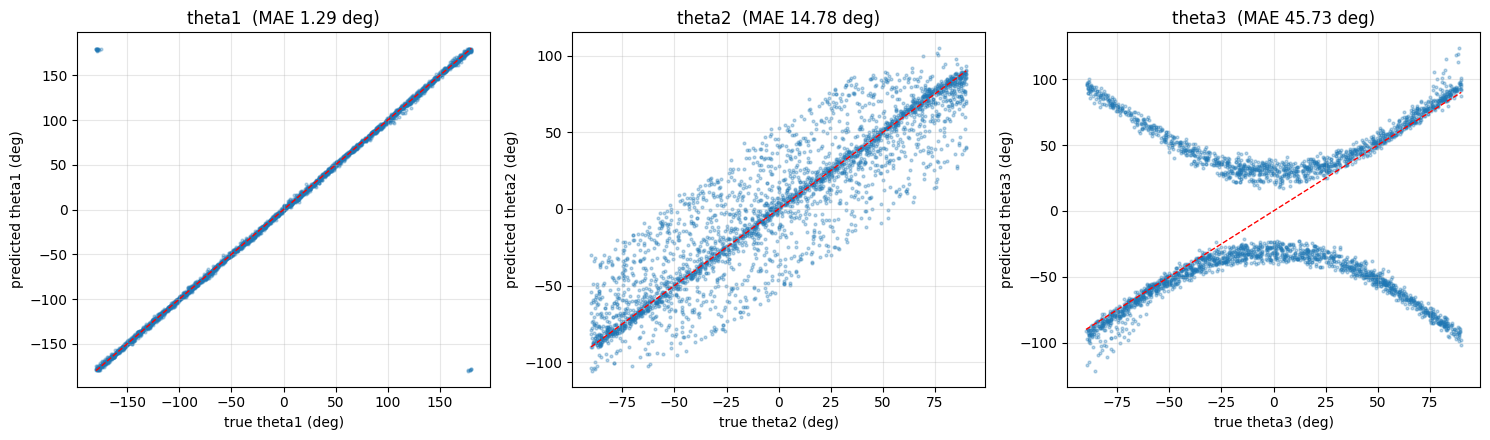

In [ ]:
## ---- Predicted vs. true, per joint (test set) ----
# Note: theta1's scatter can show points near opposite plot corners (e.g. true
# ~+179 deg vs predicted ~-179 deg) even for an accurate model -- that's a
# plotting artifact of the +-180 deg wrap, not an error (mae_degrees above
# already accounts for it via circular distance).
joint_names = ["theta1", "theta2", "theta3"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, ax in enumerate(axes):
    true_deg = np.degrees(Y_test_raw[i])
    pred_deg = np.degrees(test_pred_theta[i])
    ax.scatter(true_deg, pred_deg, s=4, alpha=0.3)
    lo, hi = true_deg.min(), true_deg.max()
    ax.plot([lo, hi], [lo, hi], "r--", linewidth=1)
    ax.set_xlabel(f"true {joint_names[i]} (deg)")
    ax.set_ylabel(f"predicted {joint_names[i]} (deg)")
    ax.set_title(f"{joint_names[i]}  (MAE {test_joint_mae[i]:.2f} deg)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
## ---- Singularity proximity proxies (test set) ----
theta3_true = Y_test_raw[2]
r_true = np.sqrt(X_test_xyz[0] ** 2 + X_test_xyz[1] ** 2)

elbow_proxy = np.abs(np.sin(theta3_true))  # -> 0 near elbow singularity (theta3 -> 0)
base_proxy = r_true                        # -> 0 near base singularity

corr_elbow = np.corrcoef(test_pose_err, elbow_proxy)[0, 1]
corr_base = np.corrcoef(test_pose_err, base_proxy)[0, 1]

print(f"corr(pose_err, |sin(theta3)|)  [elbow singularity proxy]: {corr_elbow:.3f}")
print(f"corr(pose_err, r)              [base singularity proxy]:  {corr_base:.3f}")
print("(negative correlation = error grows as the proxy shrinks, i.e. error grows near that singularity)")

# ---- Worst-error decile vs. overall ----
worst_cut = np.percentile(test_pose_err, 90)
worst_mask = test_pose_err >= worst_cut
print(f"\nWorst decile (n={worst_mask.sum()} of {len(test_pose_err)}):")
print(f"  mean |sin(theta3)|: {elbow_proxy[worst_mask].mean():.3f}  vs overall: {elbow_proxy.mean():.3f}")
print(f"  mean r:             {base_proxy[worst_mask].mean():.3f}  vs overall: {base_proxy.mean():.3f}")

# ---- Branch-selection accuracy near each singularity ----
_, chosen_elbow_config_test, _ = predict_ik(X_test_xyz, parameters)
true_elbow_config_test = encode_elbow_config(Y_test_raw)[0]
correct_selection = chosen_elbow_config_test == true_elbow_config_test

near_elbow_sing = elbow_proxy < np.percentile(elbow_proxy, 20)
near_base_sing = base_proxy < np.percentile(base_proxy, 20)

print(f"\nSelection accuracy near elbow singularity (closest 20% to theta3=0): {correct_selection[near_elbow_sing].mean():.1%}  vs elsewhere: {correct_selection[~near_elbow_sing].mean():.1%}")
print(f"Selection accuracy near base singularity  (closest 20% to r=0):      {correct_selection[near_base_sing].mean():.1%}  vs elsewhere: {correct_selection[~near_base_sing].mean():.1%}")

print(f"\nMean pose error near elbow singularity: {test_pose_err[near_elbow_sing].mean():.2f} mm  vs elsewhere: {test_pose_err[~near_elbow_sing].mean():.2f} mm")
print(f"Mean pose error near base singularity:  {test_pose_err[near_base_sing].mean():.2f} mm  vs elsewhere: {test_pose_err[~near_base_sing].mean():.2f} mm")

corr(pose_err, |sin(theta3)|)  [elbow singularity proxy]: -0.039
corr(pose_err, r)              [base singularity proxy]:  -0.120
(negative correlation = error grows as the proxy shrinks, i.e. error grows near that singularity)

Worst decile (n=300 of 3000):
  mean |sin(theta3)|: 0.668  vs overall: 0.633
  mean r:             1.597  vs overall: 1.836

Selection accuracy near elbow singularity (closest 20% to theta3=0): 47.7%  vs elsewhere: 58.3%
Selection accuracy near base singularity  (closest 20% to r=0):      81.5%  vs elsewhere: 49.9%

Mean pose error near elbow singularity: 82.42 mm  vs elsewhere: 71.99 mm
Mean pose error near base singularity:  87.23 mm  vs elsewhere: 70.79 mm
